In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.ticker as ticker

# Works when Jupyter starts in the project root or notebooks/.
notebook_dir = next(
    (p / "notebooks" if (p / "notebooks" / "events.ipynb").is_file() else p)
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "notebooks" / "events.ipynb").is_file()
    or (p / "events.ipynb").is_file()
)
CSV_PATH = notebook_dir / "data/supabase_exports/20261028T050019Z_hxekxttx/events.csv"
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"Events CSV not found: {CSV_PATH}")
FIGURE_DIR = notebook_dir / "events_eda" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Read only the fields needed for the date-based plots; \N is a missing value.
events = pd.read_csv(
    CSV_PATH, usecols=["slug", "start_date", "end_date"], na_values=[r"\N"]
)
if events.empty:
    raise ValueError("The events export is empty.")
for column in ["start_date", "end_date"]:
    events[column] = pd.to_datetime(
        events[column], format="mixed", utc=True, errors="raise"
    )


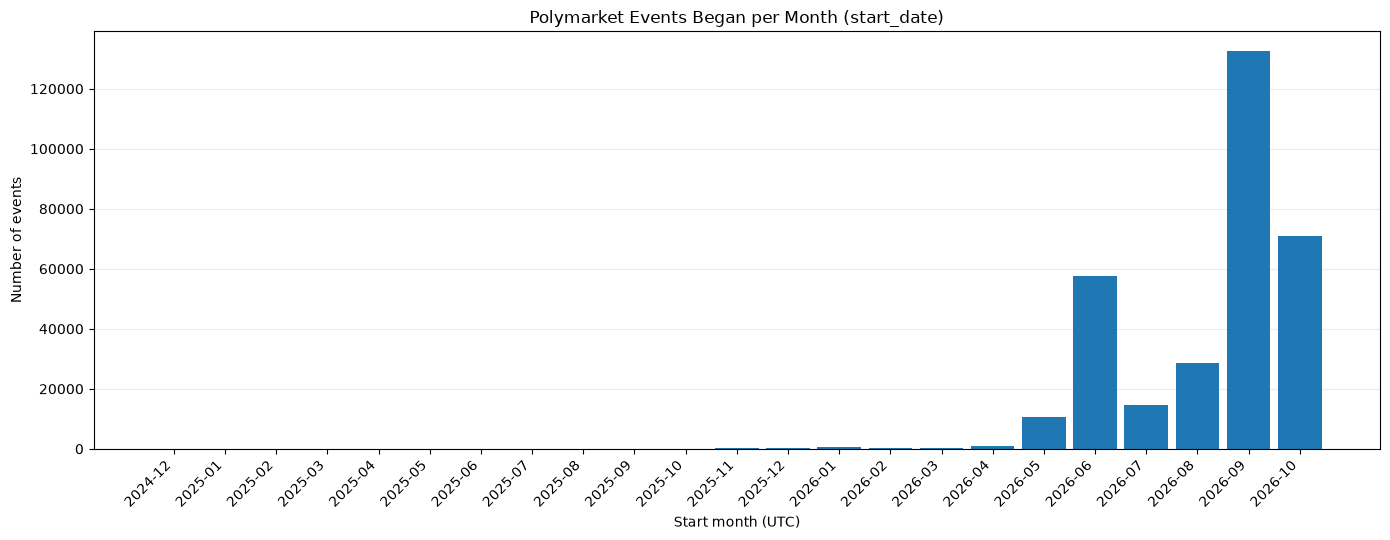

Total rows: 327,432; valid start dates: 317,871; missing: 9,561
Range: 2024-12 through 2026-10


In [2]:
# Count events by reported start month in UTC, including empty months.
start_dates = events["start_date"].dropna()
if start_dates.empty:
    raise ValueError("No events have a start date to plot.")
monthly_counts = (
    start_dates.dt.tz_localize(None).dt.to_period("M").value_counts().sort_index()
)
monthly_counts = monthly_counts.reindex(
    pd.period_range(monthly_counts.index.min(), monthly_counts.index.max(), freq="M"),
    fill_value=0,
)
total_rows = len(events)
missing_start_dates = int(events["start_date"].isna().sum())

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.bar(range(len(monthly_counts)), monthly_counts.values, width=0.85)
step = max(1, len(monthly_counts) // 18)
ax.set_xticks(range(0, len(monthly_counts), step))
ax.set_xticklabels([str(x) for x in monthly_counts.index[::step]], rotation=45, ha="right")
ax.set_title("Polymarket Events Began per Month (start_date)")
ax.set_xlabel("Start month (UTC)")
ax.set_ylabel("Number of events")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "polymarket_events_by_start_month.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Total rows: {total_rows:,}; valid start dates: {total_rows-missing_start_dates:,}; missing: {missing_start_dates:,}")
print(f"Range: {monthly_counts.index.min()} through {monthly_counts.index.max()}")


Rows: 327432 Valid durations: 317585 Negative durations: 36
count    317549.000000
mean          7.753577
std          36.277907
min           0.000000
25%           0.997206
50%           1.004195
75%           7.332523
90%          12.506032
95%          13.593322
99%         167.448346
max        1446.297475


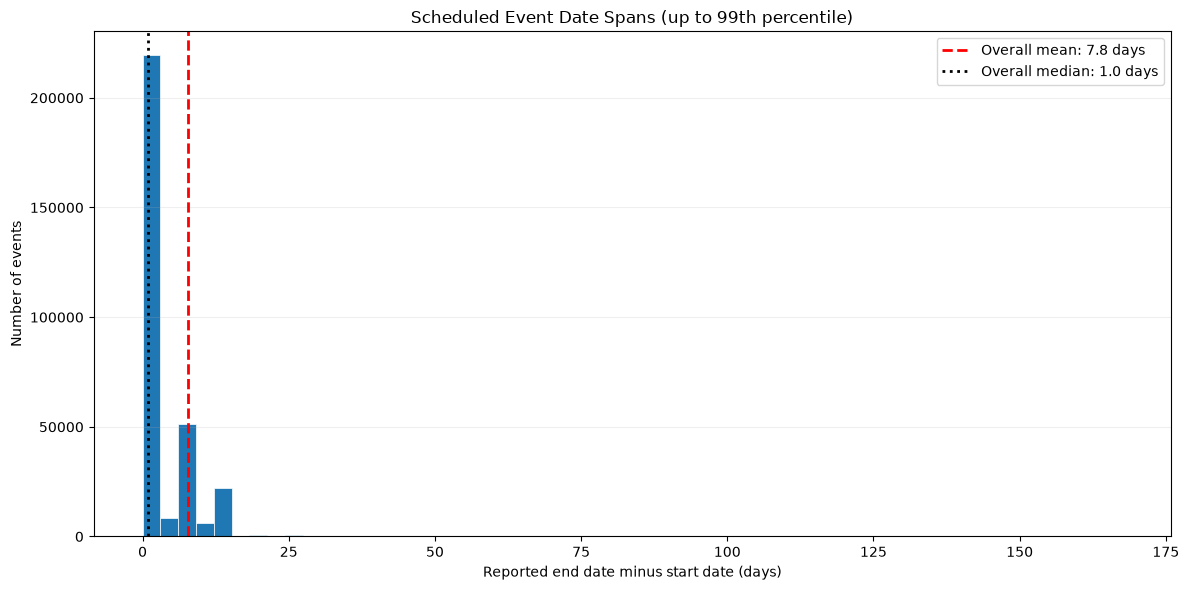

99th percentile cutoff: 167.44834629629642 Shown: 314373 Excluded long tail: 3176


In [3]:
duration = (events["end_date"] - events["start_date"]).dt.total_seconds() / 86400

valid = duration.dropna()
nonnegative = valid[valid >= 0]
if nonnegative.empty:
    raise ValueError("No nonnegative event date spans are available to plot.")
negative_count = (valid < 0).sum()
print("Rows:", len(events), "Valid durations:", len(valid), "Negative durations:", negative_count)
print(nonnegative.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_string())

# Display central distribution with a separately labeled exclusion of long-tail values
cutoff = nonnegative.quantile(.99)
shown = nonnegative[nonnegative <= cutoff]
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(shown, bins=55, edgecolor="white", linewidth=.5)
ax.axvline(nonnegative.mean(), linestyle="--", color="red", linewidth=2, label=f"Overall mean: {nonnegative.mean():,.1f} days")
ax.axvline(nonnegative.median(), linestyle=":", color="black", linewidth=2, label=f"Overall median: {nonnegative.median():,.1f} days")
ax.set_title("Scheduled Event Date Spans (up to 99th percentile)")
ax.set_xlabel("Reported end date minus start date (days)")
ax.set_ylabel("Number of events")
ax.legend()
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
out = FIGURE_DIR / "polymarket_event_duration_histogram.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("99th percentile cutoff:", cutoff, "Shown:",len(shown), "Excluded long tail:",len(nonnegative)-len(shown))


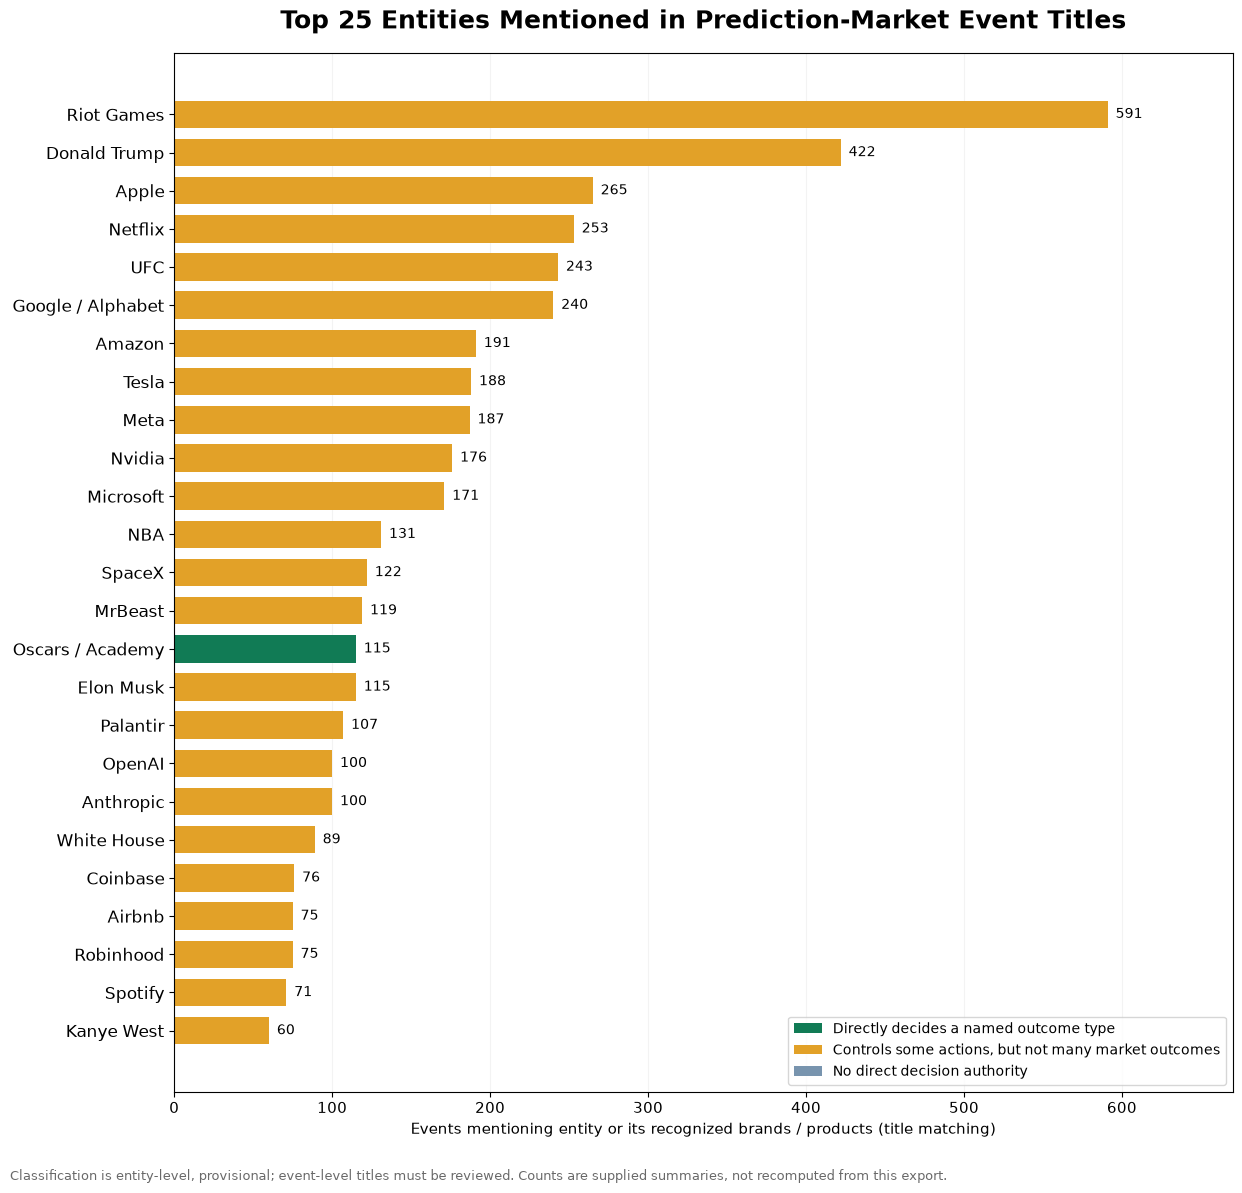

In [6]:
data = {
    "Entity": [
        "Riot Games",
        "Donald Trump",
        "Apple",
        "Netflix",
        "UFC",
        "Google / Alphabet",
        "Amazon",
        "Tesla",
        "Meta",
        "Nvidia",
        "Microsoft",
        "NBA",
        "SpaceX",
        "MrBeast",
        "Oscars / Academy",
        "Elon Musk",
        "Palantir",
        "OpenAI",
        "Anthropic",
        "White House",
        "Coinbase",
        "Airbnb",
        "Robinhood",
        "Spotify",
        "Kanye West"
    ],
    "Event Count": [
        591, 422, 265, 253, 243,
        240, 191, 188, 187, 176,
        171, 131, 122, 119, 115,
        115, 107, 100, 100, 89,
        76, 75, 75, 71, 60
    ]
}

df = pd.DataFrame(data)

df["Classification"] = (
    "Controls some actions, but not many market outcomes"
)

df.loc[
    df["Entity"] == "Oscars / Academy",
    "Classification"
] = "Directly decides a named outcome type"

color_map = {
    "Directly decides a named outcome type": "#117B55",
    "Controls some actions, but not many market outcomes": "#E2A128",
    "No direct decision authority": "#7894AE"
}

df["Color"] = df["Classification"].map(color_map)

fig, ax = plt.subplots(figsize=(12.5, 12))

y = np.arange(len(df))

bars = ax.barh(
    y,
    df["Event Count"],
    color=df["Color"],
    height=0.72
)

ax.set_yticks(y)
ax.set_yticklabels(df["Entity"], fontsize=12)

ax.invert_yaxis()

ax.set_xlim(0, 670)
ax.set_xticks(np.arange(0, 601, 100))
ax.tick_params(axis="x", labelsize=11)

ax.set_xlabel(
    "Events mentioning entity or its recognized brands / products (title matching)",
    fontsize=11
)

ax.set_title(
    "Top 25 Entities Mentioned in Prediction-Market Event Titles",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_axisbelow(True)
ax.grid(
    axis="x",
    linestyle="-",
    alpha=0.15
)

for bar, count in zip(bars, df["Event Count"]):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        str(count),
        ha="left",
        va="center",
        fontsize=10
    )

legend_elements = [
    Patch(
        facecolor="#117B55",
        label="Directly decides a named outcome type"
    ),
    Patch(
        facecolor="#E2A128",
        label="Controls some actions, but not many market outcomes"
    ),
    Patch(
        facecolor="#7894AE",
        label="No direct decision authority"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    fontsize=10,
    frameon=True
)

fig.text(
    0.01,
    0.012,
    "Classification is entity-level, provisional; event-level titles must be reviewed. "
    "Counts are supplied summaries, not recomputed from this export.",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.035, 1, 1])

plt.savefig(
    FIGURE_DIR / "top25_outcome_entities.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


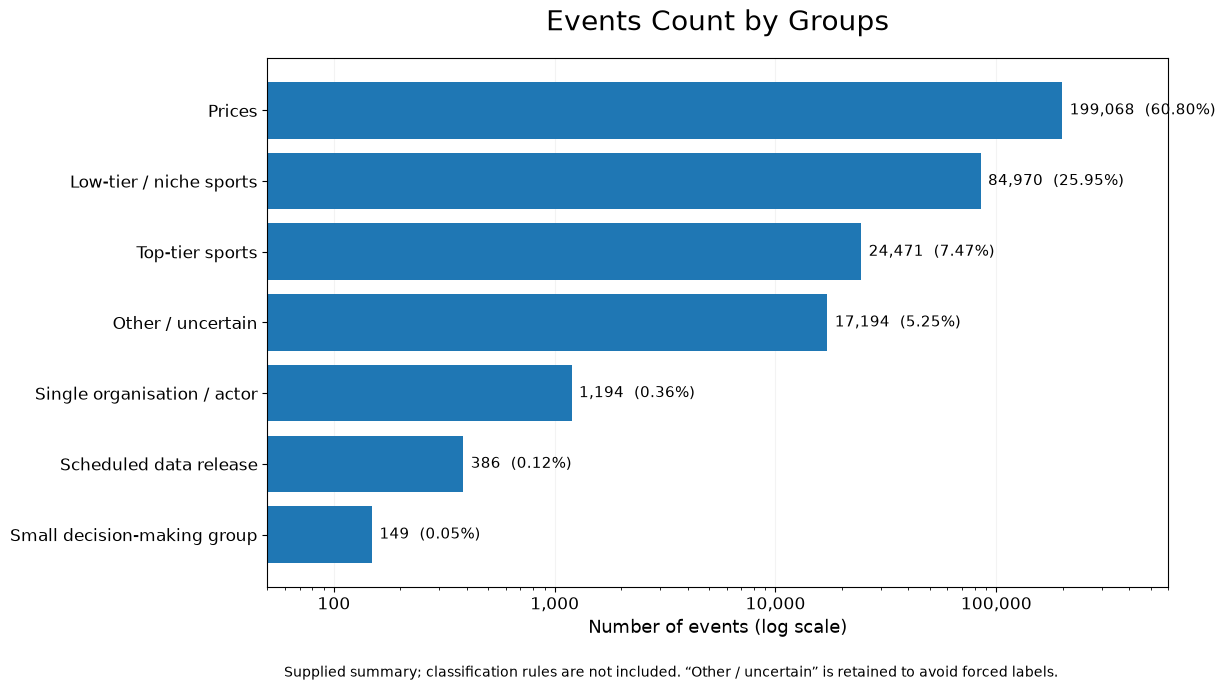

In [8]:
# Supplied counts attributed to information_access_summary.csv.
# That source file and its classification rules are not included in this folder.
data = {
    "access_class": [
        "Prices",
        "Low-tier / niche sports",
        "Top-tier sports",
        "Other / uncertain",
        "Single organisation / actor",
        "Scheduled data release",
        "Small decision-making group"
    ],
    "events": [
        199068,
        84970,
        24471,
        17194,
        1194,
        386,
        149
    ],
    "pct_all": [
        60.80,
        25.95,
        7.47,
        5.25,
        0.36,
        0.12,
        0.05
    ]
}

df = pd.DataFrame(data)
# Derive percentages consistently from the supplied counts.
df["pct_all"] = 100 * df["events"] / df["events"].sum()

# Reverse order for horizontal bar chart
df = df.iloc[::-1]

# Figure
fig, ax = plt.subplots(figsize=(12.3, 7))

# Horizontal bars
bars = ax.barh(
    df["access_class"],
    df["events"],
    color="#1f77b4",
    height=0.8
)

# Logarithmic x-axis
ax.set_xscale("log")
ax.set_xlim(50, 600000)

# Major ticks
ax.xaxis.set_major_locator(
    ticker.LogLocator(base=10)
)
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Gridlines
ax.grid(
    axis="x",
    which="major",
    alpha=0.15
)
ax.set_axisbelow(True)

# Value and percentage labels
for bar, count, pct in zip(
    bars, df["events"], df["pct_all"]
):
    ax.text(
        count * 1.08,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}  ({pct:.2f}%)",
        va="center",
        ha="left",
        fontsize=11
    )

# Title and axis labels
ax.set_title(
    "Events Count by Groups",
    fontsize=20,
    pad=20
)

ax.set_xlabel(
    "Number of events (log scale)",
    fontsize=13
)

ax.set_ylabel("")

ax.tick_params(axis="both", labelsize=12)

# Footnote
fig.text(
    0.235,
    0.025,
    'Supplied summary; classification rules are not included. '
    '“Other / uncertain” is retained to avoid forced labels.',
    ha="left",
    fontsize=10
)

# Layout
plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()
plt.close(fig)
